In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import time
import random

print("Risk-Aware Intelligent Agent Project")
print("Libraries imported successfully!")

Risk-Aware Intelligent Agent Project
Libraries imported successfully!


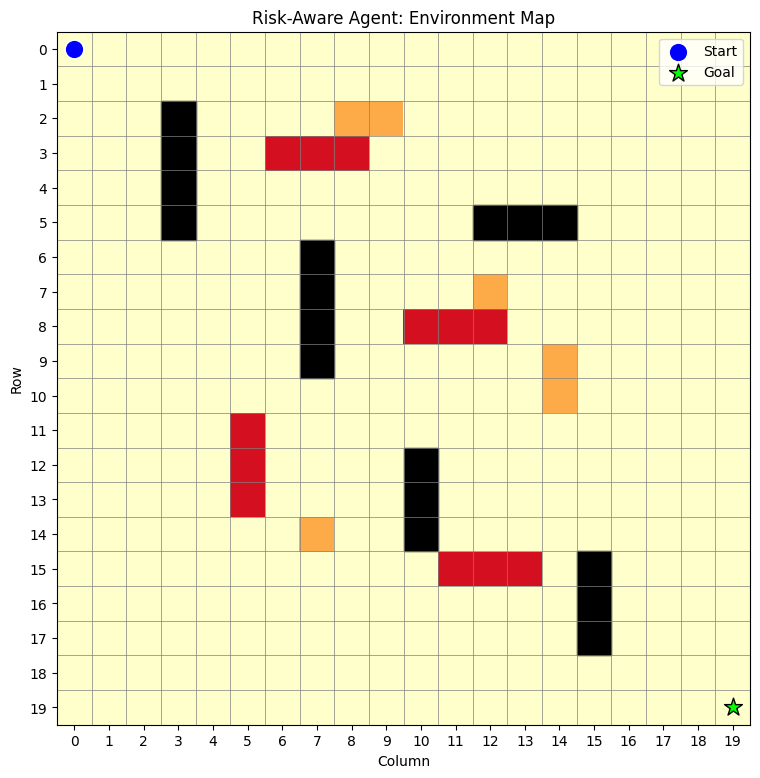

Grid created successfully!
Grid size: 20 x 20
Number of obstacles: 17
Start: (0, 0)
Goal: (19, 19)


In [ ]:

# STEP 2: CREATE THE GRID ENVIRONMENT

GRID_SIZE = 20

# 0 = free cell, 1 = obstacle
grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

# Risk map: values range from 0.0 to 1.0
risk_map = np.zeros((GRID_SIZE, GRID_SIZE), dtype=float)

# Starting point and destination: (row, column)
start = (0, 0)
goal = (19, 19)

# Add fixed obstacles
obstacles = [
    (2, 3), (3, 3), (4, 3), (5, 3),
    (6, 7), (7, 7), (8, 7), (9, 7),
    (12, 10), (13, 10), (14, 10),
    (15, 15), (16, 15), (17, 15),
    (5, 12), (5, 13), (5, 14)
]

for cell in obstacles:
    grid[cell] = 1

# Add high-risk zones
risk_zones = [
    (3, 6), (3, 7), (3, 8),
    (8, 10), (8, 11), (8, 12),
    (11, 5), (12, 5), (13, 5),
    (15, 11), (15, 12), (15, 13)
]

for cell in risk_zones:
    risk_map[cell] = 0.8

# Add a few medium-risk cells
medium_risk_zones = [
    (2, 8), (2, 9), (7, 12),
    (9, 14), (10, 14), (14, 7)
]

for cell in medium_risk_zones:
    risk_map[cell] = 0.4

# Visualize the environment
fig, ax = plt.subplots(figsize=(9, 9))

ax.imshow(risk_map, cmap="YlOrRd", vmin=0, vmax=1)

# Draw obstacles
for row, col in zip(*np.where(grid == 1)):
    ax.add_patch(plt.Rectangle(
        (col - 0.5, row - 0.5),
        1, 1, color="black"
    ))

# Mark start and goal
ax.scatter(start[1], start[0], color="blue",
           s=180, label="Start", edgecolors="white")

ax.scatter(goal[1], goal[0], color="lime",
           s=180, marker="*", label="Goal",
           edgecolors="black")

ax.set_xticks(range(GRID_SIZE))
ax.set_yticks(range(GRID_SIZE))
ax.set_xticklabels(range(GRID_SIZE))
ax.set_yticklabels(range(GRID_SIZE))
ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
ax.grid(which="minor", color="gray", linewidth=0.5)
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_title("Risk-Aware Agent: Environment Map")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.legend()
plt.show()

print("Grid created successfully!")
print("Grid size:", GRID_SIZE, "x", GRID_SIZE)
print("Number of obstacles:", len(obstacles))
print("Start:", start)
print("Goal:", goal)


In [ ]:

# STEP 3: BASELINE SEARCH ALGORITHMS

from collections import deque
import heapq
import time

# Four possible movements: up, down, left, right
MOVES = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]

def get_neighbors(position, grid):
    """Return valid neighboring cells."""
    row, col = position
    neighbors = []

    for dr, dc in MOVES:
        nr, nc = row + dr, col + dc

        if (0 <= nr < grid.shape[0] and
            0 <= nc < grid.shape[1] and
            grid[nr, nc] == 0):
            neighbors.append((nr, nc))

    return neighbors


def reconstruct_path(parent, start, goal):
    """Reconstruct the path from start to goal."""
    if goal != start and goal not in parent:
        return []

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(grid, start, goal):
    """Breadth-First Search for an unweighted grid."""
    queue = deque([start])
    parent = {start: None}
    expanded = 0

    while queue:
        current = queue.popleft()
        expanded += 1

        if current == goal:
            break

        for neighbor in get_neighbors(current, grid):
            if neighbor not in parent:
                parent[neighbor] = current
                queue.append(neighbor)

    path = reconstruct_path(parent, start, goal)

    return {
        "path": path,
        "cost": len(path) - 1 if path else float("inf"),
        "expanded": expanded
    }


def heuristic(position, goal):
    """Manhattan distance for four-directional movement."""
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


def astar(grid, start, goal):
    """Standard A* using movement cost only."""
    open_heap = []
    heapq.heappush(
        open_heap,
        (heuristic(start, goal), 0, start)
    )

    parent = {start: None}
    g_cost = {start: 0}
    expanded = 0

    while open_heap:
        f, current_g, current = heapq.heappop(open_heap)

        # Ignore outdated queue entries
        if current_g != g_cost.get(current):
            continue

        expanded += 1

        if current == goal:
            break

        for neighbor in get_neighbors(current, grid):
            new_g = current_g + 1

            if new_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = new_g
                parent[neighbor] = current

                new_f = new_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (new_f, new_g, neighbor)
                )

    path = reconstruct_path(parent, start, goal)

    return {
        "path": path,
        "cost": len(path) - 1 if path else float("inf"),
        "expanded": expanded
    }


# Run both algorithms
bfs_result = bfs(grid, start, goal)
astar_result = astar(grid, start, goal)

print("===== BFS RESULT =====")
print("Path length:", bfs_result["cost"])
print("Nodes expanded:", bfs_result["expanded"])
print("Path found:", bool(bfs_result["path"]))

print("\n===== STANDARD A* RESULT =====")
print("Path length:", astar_result["cost"])
print("Nodes expanded:", astar_result["expanded"])
print("Path found:", bool(astar_result["path"]))


===== BFS RESULT =====
Path length: 38
Nodes expanded: 383
Path found: True

===== STANDARD A* RESULT =====
Path length: 38
Nodes expanded: 383
Path found: True


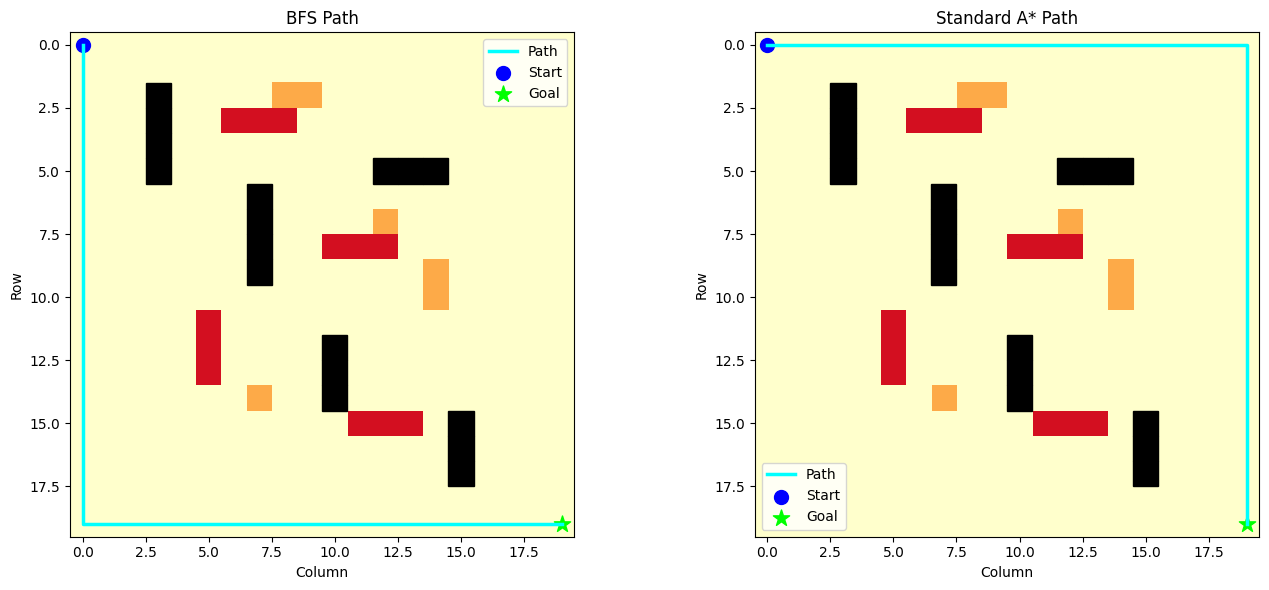

In [ ]:

# VISUALIZE BFS AND A* PATHS

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

results = [
    ("BFS Path", bfs_result),
    ("Standard A* Path", astar_result)
]

for ax, (title, result) in zip(axes, results):
    ax.imshow(risk_map, cmap="YlOrRd", vmin=0, vmax=1)

    # Obstacles
    for row, col in zip(*np.where(grid == 1)):
        ax.add_patch(plt.Rectangle(
            (col - 0.5, row - 0.5),
            1, 1, color="black"
        ))

    # Draw path
    path = result["path"]

    if path:
        rows = [p[0] for p in path]
        cols = [p[1] for p in path]

        ax.plot(cols, rows, color="cyan",
                linewidth=2.5, label="Path")

    ax.scatter(start[1], start[0], color="blue",
               s=100, label="Start")

    ax.scatter(goal[1], goal[0], color="lime",
               s=150, marker="*", label="Goal")

    ax.set_title(title)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.legend()

plt.tight_layout()
plt.show()


In [ ]:
def risk_aware_astar(grid, risk_map, start, goal, risk_weight=10.0):
    open_heap = []
    heapq.heappush(
        open_heap,
        (heuristic(start, goal), 0.0, start)
    )

    parent = {start: None}
    g_cost = {start: 0.0}
    expanded = 0

    while open_heap:
        f, current_g, current = heapq.heappop(open_heap)

        # Ignore outdated queue entries
        if current_g > g_cost.get(current, float("inf")):
            continue

        expanded += 1

        if current == goal:
            break

        for neighbor in get_neighbors(current, grid):

            # Movement cost + environmental risk penalty
            movement_cost = 1.0
            risk_cost = risk_weight * risk_map[neighbor]
            new_g = current_g + movement_cost + risk_cost

            if new_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = new_g
                parent[neighbor] = current

                # Manhattan distance is an admissible heuristic
                new_f = new_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (new_f, new_g, neighbor)
                )

    path = reconstruct_path(parent, start, goal)

    if path:
        total_risk = sum(risk_map[cell] for cell in path[1:])
        path_length = len(path) - 1
        total_cost = g_cost[goal]
    else:
        total_risk = 0.0
        path_length = float("inf")
        total_cost = float("inf")

    return {
        "path": path,
        "length": path_length,
        "risk": total_risk,
        "cost": total_cost,
        "expanded": expanded
    }


# Run Risk-Aware A*
risk_result = risk_aware_astar(
    grid, risk_map, start, goal,
    risk_weight=10.0
)

print("===== RISK-AWARE A* RESULT =====")
print("Path found:", bool(risk_result["path"]))
print("Path length:", risk_result["length"], "steps")
print("Accumulated risk:", round(risk_result["risk"], 2))
print("Total weighted cost:", round(risk_result["cost"], 2))
print("Nodes expanded:", risk_result["expanded"])

===== RISK-AWARE A* RESULT =====
Path found: True
Path length: 38 steps
Accumulated risk: 0.0
Total weighted cost: 38.0
Nodes expanded: 364


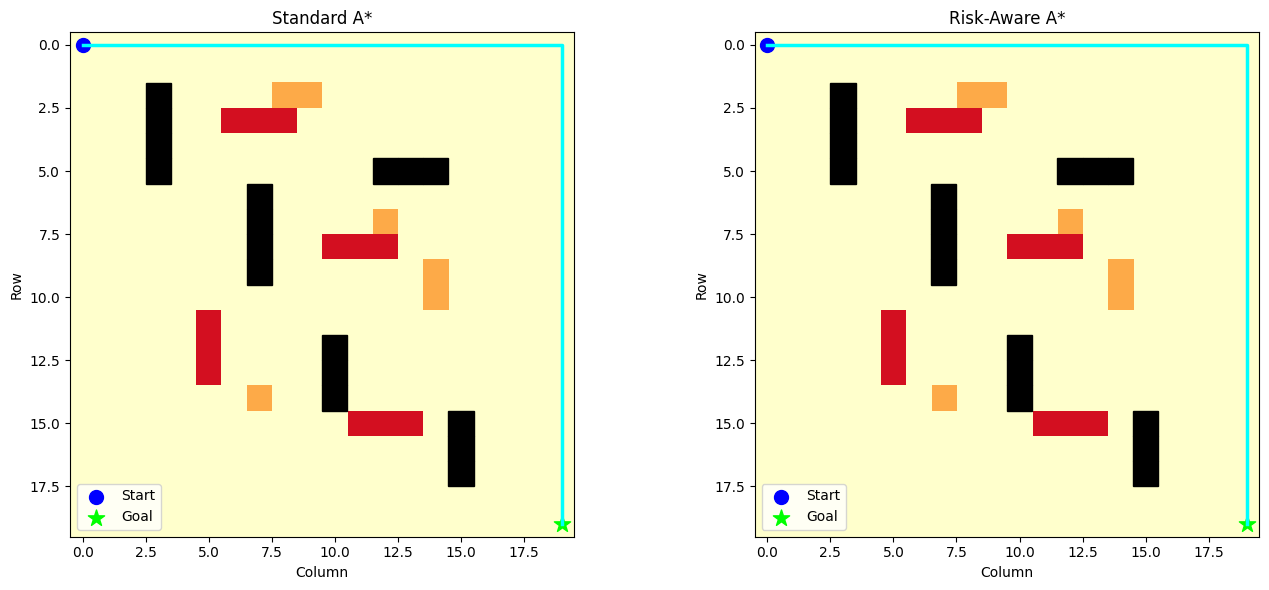

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

results = [
    ("Standard A*", astar_result),
    ("Risk-Aware A*", risk_result)
]

for ax, (title, result) in zip(axes, results):

    ax.imshow(risk_map, cmap="YlOrRd", vmin=0, vmax=1)

    # Display obstacles in black
    for row, col in zip(*np.where(grid == 1)):
        ax.add_patch(
            plt.Rectangle(
                (col - 0.5, row - 0.5),
                1, 1, color="black"
            )
        )

    path = result["path"]

    if path:
        rows = [cell[0] for cell in path]
        cols = [cell[1] for cell in path]
        ax.plot(cols, rows, color="cyan", linewidth=2.5)

    ax.scatter(start[1], start[0], color="blue",
               s=100, label="Start")

    ax.scatter(goal[1], goal[0], color="lime",
               s=150, marker="*", label="Goal")

    ax.set_title(title)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

def calculate_path_risk(path, risk_map):
    if not path:
        return float("inf")
    return sum(risk_map[cell] for cell in path[1:])

results_table = pd.DataFrame([
    {
        "Algorithm": "BFS",
        "Path Length": bfs_result["cost"],
        "Accumulated Risk": calculate_path_risk(
            bfs_result["path"], risk_map
        ),
        "Total Cost": bfs_result["cost"],
        "Nodes Expanded": bfs_result["expanded"]
    },
    {
        "Algorithm": "Standard A*",
        "Path Length": astar_result["cost"],
        "Accumulated Risk": calculate_path_risk(
            astar_result["path"], risk_map
        ),
        "Total Cost": astar_result["cost"],
        "Nodes Expanded": astar_result["expanded"]
    },
    {
        "Algorithm": "Risk-Aware A*",
        "Path Length": risk_result["length"],
        "Accumulated Risk": risk_result["risk"],
        "Total Cost": risk_result["cost"],
        "Nodes Expanded": risk_result["expanded"]
    }
])

results_table["Accumulated Risk"] = results_table[
    "Accumulated Risk"
].round(2)

results_table["Total Cost"] = results_table[
    "Total Cost"
].round(2)

display(results_table)

,Algorithm,Path Length,Accumulated Risk,Total Cost,Nodes Expanded
0,BFS,38,0.0,38.0,383
1,Standard A*,38,0.0,38.0,383
2,Risk-Aware A*,38,0.0,38.0,364


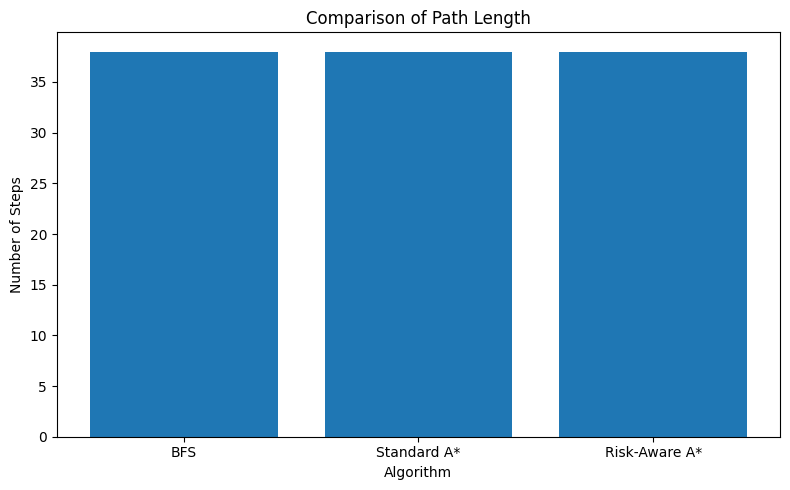

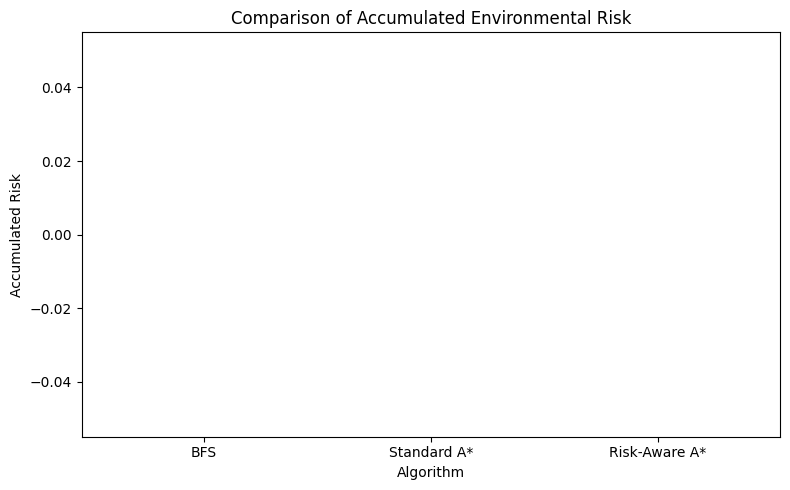

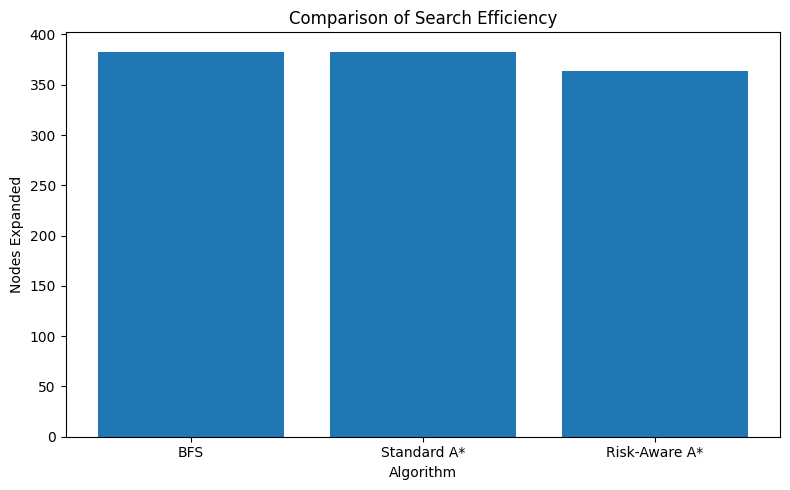

In [ ]:
# Graph 1: Path Length Comparison
plt.figure(figsize=(8, 5))
plt.bar(
    results_table["Algorithm"],
    results_table["Path Length"]
)
plt.title("Comparison of Path Length")
plt.xlabel("Algorithm")
plt.ylabel("Number of Steps")
plt.tight_layout()
plt.show()


# Graph 2: Accumulated Risk Comparison
plt.figure(figsize=(8, 5))
plt.bar(
    results_table["Algorithm"],
    results_table["Accumulated Risk"]
)
plt.title("Comparison of Accumulated Environmental Risk")
plt.xlabel("Algorithm")
plt.ylabel("Accumulated Risk")
plt.tight_layout()
plt.show()


# Graph 3: Nodes Expanded Comparison
plt.figure(figsize=(8, 5))
plt.bar(
    results_table["Algorithm"],
    results_table["Nodes Expanded"]
)
plt.title("Comparison of Search Efficiency")
plt.xlabel("Algorithm")
plt.ylabel("Nodes Expanded")
plt.tight_layout()
plt.show()

In [ ]:
# Create a separate grid for the dynamic experiment
dynamic_grid = grid.copy()

# Find cells on the current path that are not
# the start or goal
candidate_cells = [
    cell for cell in risk_result["path"][2:-1]
    if dynamic_grid[cell] == 0
]

if candidate_cells:
    # Place a new obstacle on the existing route
    new_obstacle = candidate_cells[len(candidate_cells) // 2]
    dynamic_grid[new_obstacle] = 1

    print("New obstacle appeared at:", new_obstacle)

    # Replan using Risk-Aware A*
    replanned_result = risk_aware_astar(
        dynamic_grid,
        risk_map,
        start,
        goal,
        risk_weight=10.0
    )

    print("\n===== DYNAMIC REPLANNING RESULT =====")
    print("New path found:", bool(replanned_result["path"]))
    print("New path length:", replanned_result["length"])
    print("Accumulated risk:", round(replanned_result["risk"], 2))
    print("Total weighted cost:", round(replanned_result["cost"], 2))
    print("Nodes expanded:", replanned_result["expanded"])

else:
    print("No suitable path cell found for the new obstacle.")

New obstacle appeared at: (1, 19)

===== DYNAMIC REPLANNING RESULT =====
New path found: True
New path length: 38
Accumulated risk: 0.0
Total weighted cost: 38.0
Nodes expanded: 363


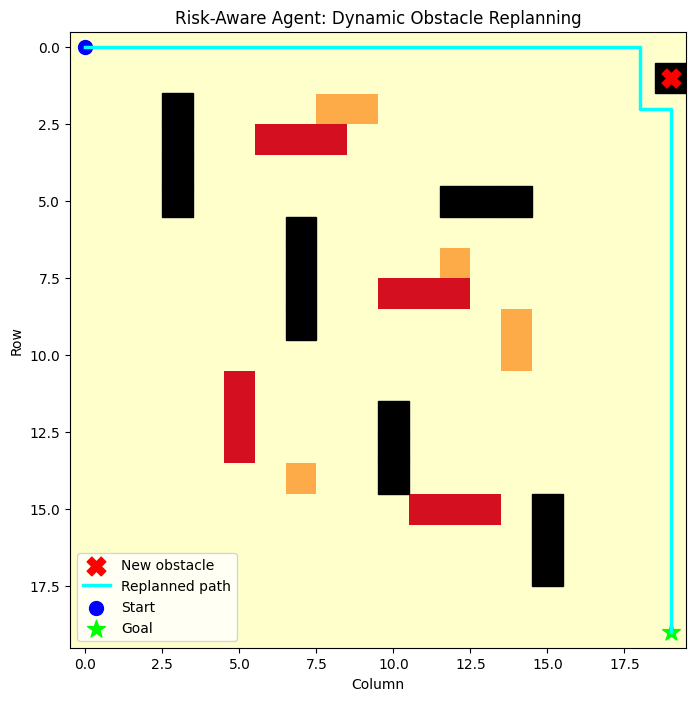

In [ ]:
plt.figure(figsize=(8, 8))

plt.imshow(risk_map, cmap="YlOrRd", vmin=0, vmax=1)

# Draw obstacles, including the new dynamic obstacle
for row, col in zip(*np.where(dynamic_grid == 1)):
    plt.gca().add_patch(
        plt.Rectangle(
            (col - 0.5, row - 0.5),
            1, 1, color="black"
        )
    )

# Show the new obstacle with a red X
plt.scatter(
    new_obstacle[1], new_obstacle[0],
    color="red", marker="X", s=180,
    label="New obstacle"
)

# Plot the replanned route
if replanned_result["path"]:
    rows = [cell[0] for cell in replanned_result["path"]]
    cols = [cell[1] for cell in replanned_result["path"]]
    plt.plot(cols, rows, color="cyan", linewidth=2.5,
             label="Replanned path")

plt.scatter(start[1], start[0], color="blue",
            s=100, label="Start")
plt.scatter(goal[1], goal[0], color="lime",
            marker="*", s=180, label="Goal")

plt.title("Risk-Aware Agent: Dynamic Obstacle Replanning")
plt.xlabel("Column")
plt.ylabel("Row")
plt.legend()
plt.show()

In [ ]:
risk_weights = [0, 2, 5, 10, 20, 50]
experiment_results = []

for weight in risk_weights:
    result = risk_aware_astar(
        grid,
        risk_map,
        start,
        goal,
        risk_weight=weight
    )

    experiment_results.append({
        "Risk Weight": weight,
        "Path Length": result["length"],
        "Accumulated Risk": round(result["risk"], 2),
        "Total Cost": round(result["cost"], 2),
        "Nodes Expanded": result["expanded"]
    })

risk_experiment_df = pd.DataFrame(experiment_results)

display(risk_experiment_df)

,Risk Weight,Path Length,Accumulated Risk,Total Cost,Nodes Expanded
0,0,38,0.0,38.0,383
1,2,38,0.0,38.0,364
2,5,38,0.0,38.0,364
3,10,38,0.0,38.0,364
4,20,38,0.0,38.0,364
5,50,38,0.0,38.0,364


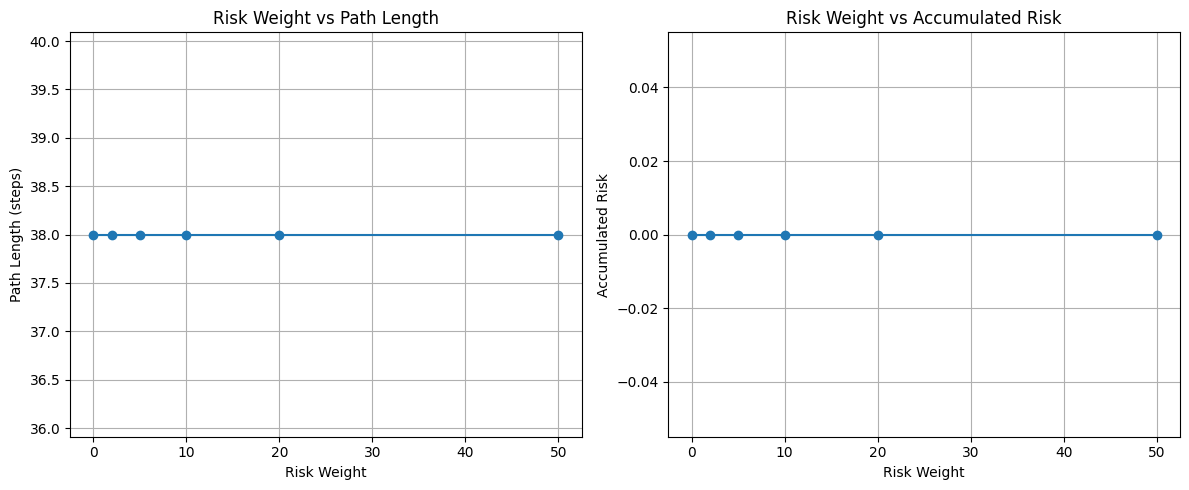

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    risk_experiment_df["Risk Weight"],
    risk_experiment_df["Path Length"],
    marker="o"
)
axes[0].set_title("Risk Weight vs Path Length")
axes[0].set_xlabel("Risk Weight")
axes[0].set_ylabel("Path Length (steps)")
axes[0].grid(True)

axes[1].plot(
    risk_experiment_df["Risk Weight"],
    risk_experiment_df["Accumulated Risk"],
    marker="o"
)
axes[1].set_title("Risk Weight vs Accumulated Risk")
axes[1].set_xlabel("Risk Weight")
axes[1].set_ylabel("Accumulated Risk")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Repeat experiments with different risk maps
NUM_TRIALS = 20
RISK_WEIGHT = 10.0

evaluation_results = []

for trial in range(NUM_TRIALS):

    # Generate a different risk map for each trial
    rng = np.random.default_rng(seed=trial)
    trial_risk_map = rng.choice(
        [0.0, 0.4, 0.8],
        size=grid.shape,
        p=[0.70, 0.20, 0.10]
    )

    # Obstacles and start/goal should not carry risk
    trial_risk_map[grid == 1] = 0.0
    trial_risk_map[start] = 0.0
    trial_risk_map[goal] = 0.0

    # Run standard A* and Risk-Aware A*
    standard = astar(grid, start, goal)

    aware = risk_aware_astar(
        grid, trial_risk_map, start, goal,
        risk_weight=RISK_WEIGHT
    )

    standard_risk = calculate_path_risk(
        standard["path"], trial_risk_map
    )

    evaluation_results.append({
        "Trial": trial + 1,
        "Standard A* Length": standard["cost"],
        "Standard A* Risk": standard_risk,
        "Risk-Aware Length": aware["length"],
        "Risk-Aware Risk": aware["risk"],
        "Risk-Aware Cost": aware["cost"]
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

print("\n===== AVERAGE RESULTS =====")
print(
    evaluation_df[
        [
            "Standard A* Length",
            "Standard A* Risk",
            "Risk-Aware Length",
            "Risk-Aware Risk",
            "Risk-Aware Cost"
        ]
    ].mean().round(2)
)

,Trial,Standard A* Length,Standard A* Risk,Risk-Aware Length,Risk-Aware Risk,Risk-Aware Cost
0,1,38,8.0,38,0.4,42.0
1,2,38,4.8,40,0.8,48.0
2,3,38,4.4,38,1.2,50.0
3,4,38,6.0,38,1.2,50.0
4,5,38,7.6,40,1.2,52.0
5,6,38,3.2,38,0.4,42.0
6,7,38,6.0,38,0.4,42.0
7,8,38,7.6,40,1.2,52.0
8,9,38,4.4,40,0.8,48.0
9,10,38,6.4,44,0.0,44.0



===== AVERAGE RESULTS =====
Standard A* Length    38.00
Standard A* Risk       5.94
Risk-Aware Length     39.20
Risk-Aware Risk        0.56
Risk-Aware Cost       44.80
dtype: float64


In [ ]:
average_standard_risk = evaluation_df[
    "Standard A* Risk"
].mean()

average_aware_risk = evaluation_df[
    "Risk-Aware Risk"
].mean()

if average_standard_risk > 0:
    risk_reduction = (
        (average_standard_risk - average_aware_risk)
        / average_standard_risk
    ) * 100

    print(
        f"Average risk reduction: {risk_reduction:.2f}%"
    )
else:
    print(
        "Average standard-path risk is zero; "
        "percentage reduction is undefined."
    )

print(
    "Average Standard A* path length:",
    round(evaluation_df["Standard A* Length"].mean(), 2)
)

print(
    "Average Risk-Aware A* path length:",
    round(evaluation_df["Risk-Aware Length"].mean(), 2)
)

Average risk reduction: 90.57%
Average Standard A* path length: 38.0
Average Risk-Aware A* path length: 39.2
